(400, 600, 3)


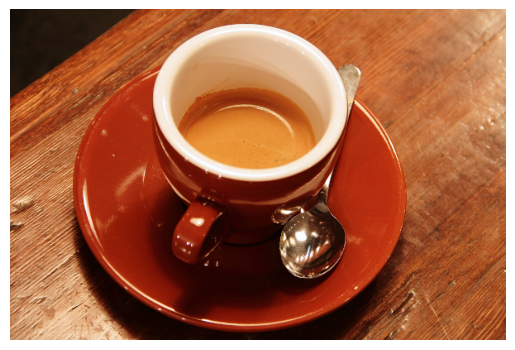

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.coffee()      # built-in sample image

print(img.shape)         # (400, 600, 3)
plt.imshow(img)
plt.axis("off")
plt.show()

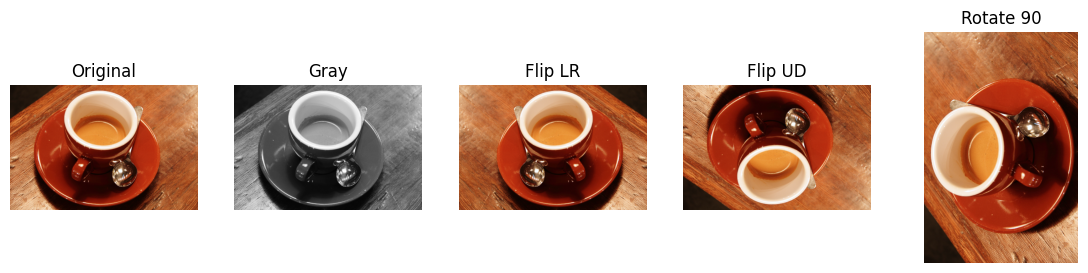

In [14]:
w = np.array([0.299, 0.587, 0.114])
gray = (img * w).sum(axis=2)               # broadcasting

flip_lr = img[:, ::-1]
flip_ud = img[::-1]
rot = np.transpose(img, (1, 0, 2))[::-1]   # rotate 90

pics = [img, gray, flip_lr, flip_ud, rot]
titles = ["Original", "Gray", "Flip LR", "Flip UD", "Rotate 90"]

plt.figure(figsize=(14, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(pics[i], cmap="gray" if i == 1 else None)
    plt.title(titles[i])
    plt.axis("off")
plt.show()

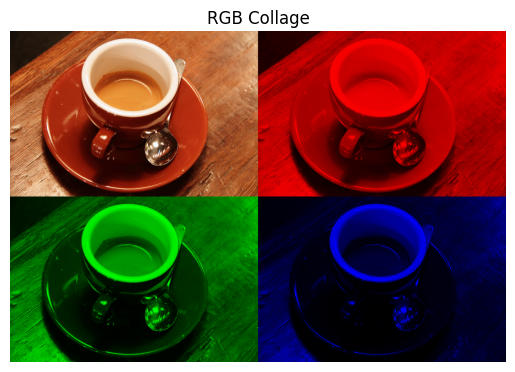

In [15]:
# split the image into red, green and blue channels
red = img.copy()
red[:, :, 1] = 0      # remove green
red[:, :, 2] = 0      # remove blue

green = img.copy()
green[:, :, 0] = 0    # remove red
green[:, :, 2] = 0    # remove blue

blue = img.copy()
blue[:, :, 0] = 0     # remove red
blue[:, :, 1] = 0     # remove green

# stack them into a collage
top = np.hstack([img, red])        # original and red side by side
bottom = np.hstack([green, blue])  # green and blue side by side
collage = np.vstack([top, bottom]) # top row above bottom row

# show the collage
plt.imshow(collage)
plt.title("RGB Collage")
plt.axis("off")
plt.show()

same result? True
Loop version:
1.88 s ± 475 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
NumPy version:
9.5 ms ± 204 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


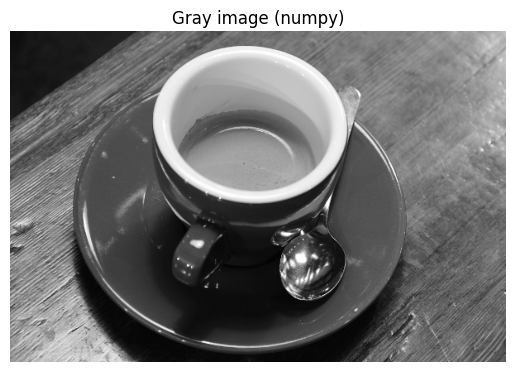

In [16]:
w = np.array([0.299, 0.587, 0.114])

# slow way - using loops
def gray_loop(im):
    h = im.shape[0]
    wd = im.shape[1]
    out = np.zeros((h, wd))
    for i in range(h):
        for j in range(wd):
            r = im[i, j, 0]
            g = im[i, j, 1]
            b = im[i, j, 2]
            out[i, j] = 0.299*r + 0.587*g + 0.114*b
    return out

# fast way - using numpy
def gray_np(im):
    return (im * w).sum(axis=2)

# checking both give same answer
print("same result?", np.allclose(gray_loop(img), gray_np(img)))

# timing both
print("Loop version:")
%timeit gray_loop(img)

print("NumPy version:")
%timeit gray_np(img)

# showing the result
plt.imshow(gray_np(img), cmap="gray")
plt.title("Gray image (numpy)")
plt.axis("off")
plt.show()